In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

/tmp/ipykernel_31667/687462750.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
DATA_PATH = '../../data'
MERGEGEN_RESULTS = '../../mergeGen/RESULTS'
SBCR_RESULTS = '../../sbcr'
ANALYSIS_PATH = '../../analysis'
INTERMEDIARY_RESULTS = f"{ANALYSIS_PATH}/intermediary_data"

MERGEGEN_DATASET = f"{MERGEGEN_RESULTS}/mergeGen_dataset1_model_dataset1_similarities.csv"
SBCR_DATASET = f"{SBCR_RESULTS}/rq1_dataset1/RESULTS/results_evaluate_dataset1_rq1_dataset1_seed-3022024.xlsx"

DATASET_COMPLETE = f"{DATA_PATH}/dataset1_complete.json" 
DATASET_TESTING = f"{DATA_PATH}/dataset1_testing.json"
DATASET_METADATA = f"{DATA_PATH}/dataset1_metadata.csv"
DATASET_STATS = f"{DATA_PATH}/dataset1_complete_stats.csv"

MERGEGEN_BETTER = f"{INTERMEDIARY_RESULTS}/rq4_dataset1_qualitative_list_MergegenBetter.csv"
SBCR_BETTER = f"{INTERMEDIARY_RESULTS}/rq4_dataset1_qualitative_list_SBCRBetter.csv"
DATASET_RESULTS = f"{INTERMEDIARY_RESULTS}/rq4_dataset1.csv"

In [3]:
df_complete_ds2 = pd.read_json(DATASET_COMPLETE)

In [4]:
df_test_ds2 = pd.read_json(DATASET_TESTING)
df_test_ds2

,all_raw_base,all_raw_a,all_raw_b,all_raw_res,chunk_id
0,private final FlowProcess<Config> flowProces...,private final FlowProcess<? extends Config> ...,/** Field LOG */\n private static final Log...,/** Field LOG */\n private static final Log...,776942
1,import java.util.Collections;\nimport java.uti...,import java.util.Collections;\nimport java.uti...,,import javax.servlet.http.HttpServletRequest;,1014100
2,import static org.mockito.Mockito.when;\nimpor...,,import static org.mockito.Mockito.when;\nimpor...,import org.junit.Assert.*;\nimport org.zanata....,1019530
3,import org.broadinstitute.sting.utils.help.Hel...,import org.broadinstitute.sting.utils.help.Hel...,import org.broadinstitute.sting.utils.help.Hel...,import org.broadinstitute.variant.variantconte...,1082450
4,mSubkeysAddedAdapter = new SubkeysAdde...,mSubkeysAddedAdapter = new SubkeysAdde...,mSubkeysList.setOnItemClickListener(ne...,mSubkeysList.setOnItemClickListener(ne...,1370321
...,...,...,...,...,...
623,if (getKeyspaces().contains(keyspaceName...,try {\n KsDef keyspaceDesc = cass...,if (getKeyspaces().contains(keyspaceName...,try {\n KsDef keyspaceDesc = cass...,936821
624,int len = mQuery.mSql.length()...,int len = mQuery.mSql.length()...,if (StrictMode.vmSqliteObjectL...,if (StrictMode.vmSqliteObjectL...,1182256
625,if (logger.isDebug...,if (logger.isDebug...,if (LOG.isDebugEna...,if (LOG.isDebugEna...,1401191
626,InetSocketAddress namenode = NameNode.getA...,"this.dfs = new DFSClient(uri, conf, statis...",InetSocketAddress namenode = NameNode.getA...,"this.dfs = new DFSClient(uri, conf, statis...",932859


In [5]:
df_mergegen_ds2 = pd.read_csv(MERGEGEN_DATASET)
df_mergegen_ds2 = df_mergegen_ds2.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})
df_mergegen_ds2

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result
0,5019,0.259615,0.272222,0.117003,1.000000,0.252577,0.626289,FAIL
1,3899,0.733333,0.741379,0.116758,0.593103,0.000000,0.296552,FAIL
2,4351,0.710843,0.716981,0.130520,0.000000,0.716981,0.358491,FAIL
3,5574,0.657143,0.671642,0.123770,0.494382,0.537143,0.515762,FAIL
4,6210,0.250373,0.259194,1.323702,0.000000,0.510092,0.255046,FAIL
...,...,...,...,...,...,...,...,...
623,5998,0.685417,0.804124,1.324466,0.764862,0.732394,0.748628,SUCCEED
624,4227,0.662712,0.754717,1.319163,0.446171,0.769032,0.607602,SUCCEED
625,5516,1.000000,1.000000,0.227891,0.615942,0.800000,0.707971,SUCCEED
626,814,0.685417,0.804124,1.318304,0.764862,0.732394,0.748628,SUCCEED


In [6]:
df_mergegen_ds2.describe()

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim
count,628.000000,628.000000,628.000000,628.000000,628.000000,628.000000,628.000000
mean,3186.826433,0.922931,0.923022,0.397476,0.684631,0.664965,0.674798
std,1783.523962,0.150310,0.153027,0.339692,0.294746,0.296725,0.219564
min,4.000000,0.211321,0.082251,0.051868,0.000000,0.000000,0.066852
25%,1629.750000,0.937367,0.940939,0.156820,0.578026,0.545694,0.530454
50%,3241.500000,1.000000,1.000000,0.277324,0.773601,0.750887,0.738113
75%,4676.000000,1.000000,1.000000,0.509618,0.912343,0.895033,0.845201
max,6240.000000,1.000000,1.000000,1.331165,1.000000,1.000000,0.983675


In [7]:
df_mergegen_ds2['chunk_id'] = df_mergegen_ds2['chunk_index'].apply(lambda idx: df_complete_ds2.loc[idx, 'chunk_id'])
df_mergegen_ds2 = df_mergegen_ds2.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})
df_mergegen_ds2.sort_values('chunk_id')

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result,chunk_id
187,4,1.000000,1.000000,0.249119,0.512563,0.972222,0.742393,SUCCEED,776942
178,7,1.000000,0.994764,0.233733,0.933702,0.838906,0.886304,SUCCEED,777222
446,19,0.967742,1.000000,0.751554,0.973190,0.551456,0.762323,SUCCEED,777715
145,53,0.530120,0.545455,0.163389,0.321429,0.724138,0.522783,FAIL,777972
152,55,0.752577,0.804533,1.326094,0.000000,0.802260,0.401130,FAIL,777981
...,...,...,...,...,...,...,...,...,...
449,6208,1.000000,1.000000,0.254737,0.981308,0.437956,0.709632,SUCCEED,1653719
4,6210,0.250373,0.259194,1.323702,0.000000,0.510092,0.255046,FAIL,1653901
314,6228,1.000000,1.000000,0.153870,0.000000,0.821918,0.410959,SUCCEED,1656072
602,6236,1.000000,1.000000,0.280683,0.923977,0.858696,0.891336,SUCCEED,1656401


In [8]:
df_sbcr_ds2 = pd.read_excel(SBCR_DATASET)
df_sbcr_ds2 = df_sbcr_ds2.rename(columns={"solution_sim_lcs": "sim_sbcr", "time_seconds": "time_sbcr", "fitness": "fitness_sbcr"})
df_sbcr_ds2.sort_values('chunk_id')

,chunk_id,fitness_sbcr,sim_sbcr,status,time_sbcr
548,776942,0.738426,1.000000,ok,1.489457
304,777222,0.890922,0.995192,ok,0.841280
186,777715,0.776531,0.985915,ok,0.333870
585,777972,0.739558,0.918239,ok,2.215153
257,777981,0.493671,1.000000,ok,1.991492
...,...,...,...,...,...
468,1653719,0.702732,1.000000,ok,1.030614
140,1653901,0.492901,0.192205,ok,6.408932
296,1656072,0.498986,0.810680,ok,12.752023
530,1656401,0.901249,0.788274,ok,0.941998


In [9]:
df_results_ds2 = df_sbcr_ds2[['chunk_id', 'fitness_sbcr', 'sim_sbcr', 'time_sbcr']].merge(df_mergegen_ds2[['chunk_index', 'chunk_id', 'sim_mergegen', 'time_mergegen', 'mergegen_parents_sim']], on='chunk_id', suffixes=('_sbcr', '_mergegen'))
df_results_ds2

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim
0,938488,0.962434,0.922330,1.200660,1471,1.000000,0.175078,0.958965
1,1079827,0.497797,0.625767,11.268360,3195,1.000000,0.209426,0.318471
2,1117164,0.786942,0.786232,1.923556,3761,0.750751,0.227764,0.670922
3,945817,0.795430,0.819499,1.355437,1594,0.817844,0.423918,0.757170
4,1304099,0.459559,0.763636,8.889821,4944,1.000000,0.247783,0.397321
...,...,...,...,...,...,...,...,...
623,938165,0.819818,1.000000,10.783195,1443,1.000000,0.195416,0.819331
624,1517141,0.901249,0.788274,0.200084,5997,1.000000,0.280220,0.891336
625,934974,0.897614,0.857708,0.521170,1221,1.000000,0.463721,0.915444
626,1180810,0.591401,0.915108,1.287984,4423,0.967423,1.103757,0.566233


In [10]:
print(df_results_ds2['sim_sbcr'].isnull().sum()) 
df_results_clean = df_results_ds2.dropna(subset=['sim_sbcr', 'sim_mergegen'])

0


In [11]:
print(df_results_clean[['sim_sbcr', 'sim_mergegen', 'time_sbcr', 'time_mergegen']].describe())

         sim_sbcr  sim_mergegen   time_sbcr  time_mergegen
count  628.000000    628.000000  628.000000     628.000000
mean     0.809004      0.923022    4.786695       0.397476
std      0.200003      0.153027    4.913480       0.339692
min      0.075646      0.082251    0.100592       0.051868
25%      0.687125      0.940939    0.692114       0.156820
50%      0.865125      1.000000    2.556238       0.277324
75%      1.000000      1.000000   10.520015       0.509618
max      1.000000      1.000000   45.932123       1.331165


In [12]:
df_results_clean['diff'] = df_results_clean['sim_sbcr'] - df_results_clean['sim_mergegen']
df_results_clean.to_csv(DATASET_RESULTS, index=False)
df_results_clean

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff
0,938488,0.962434,0.922330,1.200660,1471,1.000000,0.175078,0.958965,-0.077670
1,1079827,0.497797,0.625767,11.268360,3195,1.000000,0.209426,0.318471,-0.374233
2,1117164,0.786942,0.786232,1.923556,3761,0.750751,0.227764,0.670922,0.035481
3,945817,0.795430,0.819499,1.355437,1594,0.817844,0.423918,0.757170,0.001655
4,1304099,0.459559,0.763636,8.889821,4944,1.000000,0.247783,0.397321,-0.236364
...,...,...,...,...,...,...,...,...,...
623,938165,0.819818,1.000000,10.783195,1443,1.000000,0.195416,0.819331,0.000000
624,1517141,0.901249,0.788274,0.200084,5997,1.000000,0.280220,0.891336,-0.211726
625,934974,0.897614,0.857708,0.521170,1221,1.000000,0.463721,0.915444,-0.142292
626,1180810,0.591401,0.915108,1.287984,4423,0.967423,1.103757,0.566233,-0.052316


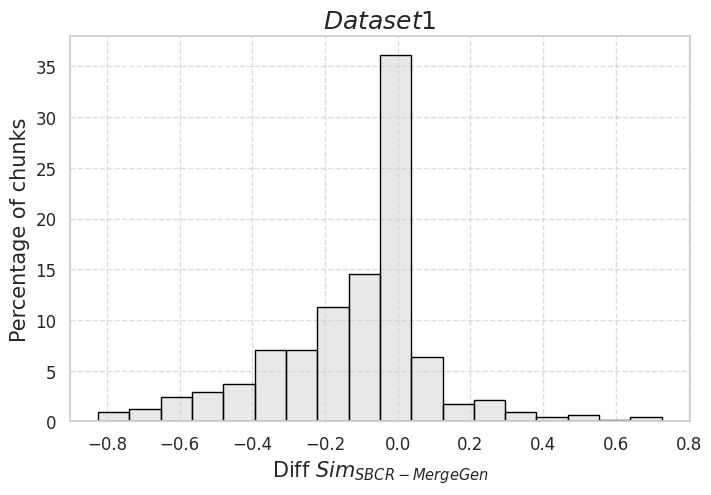

In [37]:
# close to 1 = sbcr is better
# close to -1 = mergegen is better
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)
bins = 18
plt.figure(figsize=(8, 5))
ax = sns.histplot(df_results_clean['diff'], bins=bins, stat='percent',color='lightgray', label="$Dataset1$", edgecolor='black', alpha=0.5)
# ax = sns.histplot(dataset2_Java['diff'], bins=bins, stat='percent', color='blue', label="$Dataset2_{Java}$", edgecolor='black', alpha=0.5)

plt.title('$Dataset1$')
plt.xlabel('Diff $Sim_{SBCR-MergeGen}$', fontsize=15)
plt.ylabel('Percentage of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
# plt.legend()
plt.show()

In [14]:
df_stats = pd.read_csv(DATASET_STATS)
df = df_results_clean.merge(df_stats, on='chunk_id')
df['diff_chunk_solution'] = df['chunk_size_char'] - df['solution_size_char']
df['chunk_diff_lines'] = df['v1_size'] - df['v2_size']
df['v1_size_rel'] = df['v1_size']/(df['v1_size'] + df['v2_size'])
df['v2_size_rel'] = df['v2_size']/(df['v1_size'] + df['v2_size'])
df['chunk_diff_lines_rel'] = df['v1_size_rel'] - df['v2_size_rel']
df['chunk_diff_char'] = df['v1_size_char'] - df['v2_size_char']
df['v1_size_char_rel'] = df['v1_size_char']/(df['v1_size_char'] + df['v2_size_char'])
df['v2_size_char_rel'] = df['v2_size_char']/(df['v1_size_char'] + df['v2_size_char'])
df['chunk_diff_char_rel'] = df['v1_size_char_rel'] - df['v2_size_char_rel']
df

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,resolution_parents_sim,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel
0,938488,0.962434,0.922330,1.200660,1471,1.000000,0.175078,0.958965,-0.077670,4,...,0.955436,110,0,0.500000,0.500000,0.000000,6,0.514423,0.485577,0.028846
1,1079827,0.497797,0.625767,11.268360,3195,1.000000,0.209426,0.318471,-0.374233,4,...,0.309091,63,-4,0.000000,1.000000,-1.000000,-114,0.000000,1.000000,-1.000000
2,1117164,0.786942,0.786232,1.923556,3761,0.750751,0.227764,0.670922,0.035481,7,...,0.734751,146,3,0.714286,0.285714,0.428571,117,0.643032,0.356968,0.286064
3,945817,0.795430,0.819499,1.355437,1594,0.817844,0.423918,0.757170,0.001655,17,...,0.797848,352,1,0.529412,0.470588,0.058824,-179,0.370851,0.629149,-0.258297
4,1304099,0.459559,0.763636,8.889821,4944,1.000000,0.247783,0.397321,-0.236364,6,...,0.395062,51,6,1.000000,0.000000,1.000000,147,1.000000,0.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
623,938165,0.819818,1.000000,10.783195,1443,1.000000,0.195416,0.819331,0.000000,3,...,0.819531,61,-1,0.333333,0.666667,-0.333333,-58,0.333333,0.666667,-0.333333
624,1517141,0.901249,0.788274,0.200084,5997,1.000000,0.280220,0.891336,-0.211726,5,...,0.882826,188,-1,0.400000,0.600000,-0.200000,-39,0.436893,0.563107,-0.126214
625,934974,0.897614,0.857708,0.521170,1221,1.000000,0.463721,0.915444,-0.142292,11,...,0.901977,192,-3,0.363636,0.636364,-0.272727,-69,0.428274,0.571726,-0.143451
626,1180810,0.591401,0.915108,1.287984,4423,0.967423,1.103757,0.566233,-0.052316,15,...,0.588119,50,11,0.866667,0.133333,0.733333,612,0.889313,0.110687,0.778626


In [15]:
# cases where mergeGen is better
print(len(df[df['diff'] < 0]))
df.sort_values('diff').to_csv(MERGEGEN_BETTER)
df.sort_values('diff').head(20)


380


,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,resolution_parents_sim,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel
582,1069507,0.497238,0.135417,4.461888,3090,0.960000,0.064900,0.066852,-0.824583,9,...,0.066667,338,-9,0.000000,1.000000,-1.000000,-364,0.000000,1.000000,-1.000000
165,976404,0.701895,0.205128,0.452294,2059,1.000000,0.182093,0.395299,-0.794872,11,...,0.388349,319,-7,0.181818,0.818182,-0.636364,-197,0.219373,0.780627,-0.561254
381,943842,0.584359,0.211009,0.244752,1572,0.993590,0.581760,0.599700,-0.782581,14,...,0.593941,32,12,0.928571,0.071429,0.857143,329,0.888889,0.111111,0.777778
323,790931,0.533594,0.075646,3.374950,264,0.840953,1.319180,0.467780,-0.765307,29,...,0.535738,47,27,0.965517,0.034483,0.931034,1006,0.960623,0.039377,0.921245
599,1161191,0.499187,0.247126,0.242260,4344,1.000000,0.097063,0.126506,-0.752874,10,...,0.125000,264,-10,0.000000,1.000000,-1.000000,-308,0.000000,1.000000,-1.000000
25,937543,0.473251,0.249364,0.384575,1373,1.000000,0.162744,0.115385,-0.750636,8,...,0.113164,335,-8,0.000000,1.000000,-1.000000,-384,0.000000,1.000000,-1.000000
185,1292394,0.489449,0.262414,10.189108,4802,1.000000,0.391631,0.139142,-0.737586,44,...,0.126553,1924,-44,0.000000,1.000000,-1.000000,-2250,0.000000,1.000000,-1.000000
23,975644,0.452722,0.285714,13.275231,1987,1.000000,0.104772,0.144860,-0.714286,4,...,0.143498,159,4,1.000000,0.000000,1.000000,191,1.000000,0.000000,1.000000
350,806424,0.448780,0.306306,11.724162,474,1.000000,0.098246,0.153226,-0.693694,4,...,0.150376,93,4,1.000000,0.000000,1.000000,113,1.000000,0.000000,1.000000
154,1214232,0.478680,0.299065,2.629470,4550,0.985294,0.130256,0.174935,-0.686229,8,...,0.176087,298,-8,0.000000,1.000000,-1.000000,-379,0.000000,1.000000,-1.000000


In [16]:
# cases where sbcr is better
print(len(df[df['diff'] > 0]))
df.sort_values('diff', ascending=False).to_csv(SBCR_BETTER)
df.sort_values('diff', ascending=False).head(20)

131


,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,resolution_parents_sim,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel
85,1462844,0.977612,1.000000,4.652543,5795,0.273932,1.322630,0.261128,0.726068,4,...,0.973783,126,0,0.500000,0.500000,0.000000,0,0.500000,0.500000,0.000000
37,1311711,0.618926,0.948837,0.317811,5019,0.272222,0.117003,0.626289,0.676615,7,...,0.610885,98,-5,0.142857,0.857143,-0.714286,-390,0.122093,0.877907,-0.755814
286,1360074,0.734433,0.750473,0.558341,5144,0.082251,1.321873,0.084693,0.668222,11,...,0.753123,182,-3,0.363636,0.636364,-0.272727,-193,0.304260,0.695740,-0.391481
173,1019530,0.440529,0.832432,10.924618,2565,0.249057,0.419905,0.132450,0.583376,3,...,0.403756,41,-3,0.000000,1.000000,-1.000000,-127,0.000000,1.000000,-1.000000
358,1151927,0.833926,0.836446,18.794404,4155,0.321079,1.322627,0.321650,0.515367,207,...,0.920948,4225,-5,0.487923,0.512077,-0.024155,499,0.528253,0.471747,0.056505
332,976433,0.828520,1.000000,12.178806,2062,0.516667,0.182964,0.537850,0.483333,3,...,0.827664,40,1,0.666667,0.333333,0.333333,12,0.545455,0.454545,0.090909
159,976432,0.828520,1.000000,12.677043,2061,0.516667,0.182807,0.537850,0.483333,3,...,0.827664,40,1,0.666667,0.333333,0.333333,12,0.545455,0.454545,0.090909
496,922942,0.716126,0.649733,45.932123,936,0.167447,1.317179,0.174117,0.482286,545,...,0.897408,11767,-15,0.486239,0.513761,-0.027523,2233,0.552415,0.447585,0.104831
594,778727,0.715233,0.898305,0.653456,71,0.441281,0.333626,0.698289,0.457024,11,...,0.701271,63,-7,0.181818,0.818182,-0.636364,-190,0.244624,0.755376,-0.510753
217,1414378,0.784003,1.000000,1.164133,5594,0.543162,1.316246,0.352746,0.456838,5,...,0.782187,181,-1,0.400000,0.600000,-0.200000,-235,0.301184,0.698816,-0.397631


In [17]:
df_mergegen = df[df['diff'] < 0]
df_sbcr = df[df['diff'] > 0]

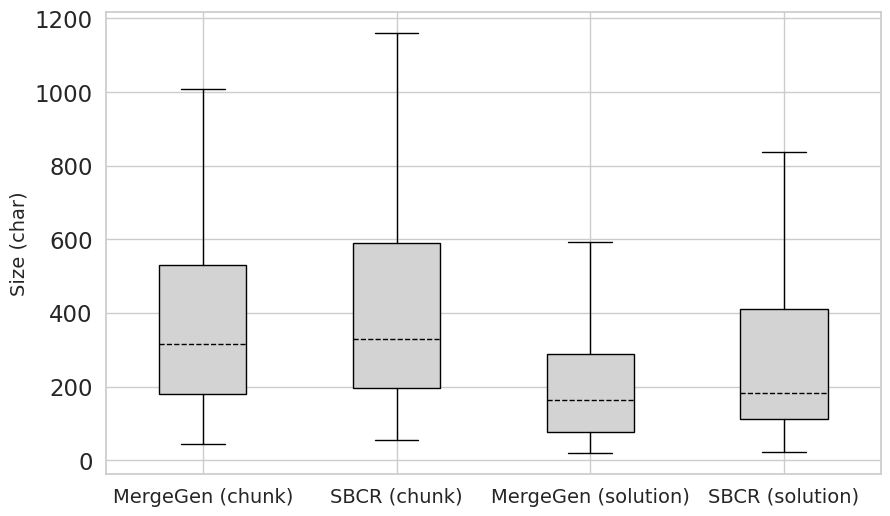

In [18]:
# Create a boxplot
plt.figure(figsize=(10, 6))  # Set the figure size
plt.boxplot([df_mergegen['chunk_size_char'], df_sbcr['chunk_size_char'], df_mergegen['solution_size_char'], df_sbcr['solution_size_char']], 
            patch_artist=True,  # To fill the box with color
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  # Color of the median line
            boxprops=dict(facecolor='lightgray', color='black'),  # Color of the box
            whiskerprops=dict(color='black'),  # Color of the whiskers
            capprops=dict(color='black'),  # Color of the caps
            showfliers=False)  # Properties of the outliers

# Customize labels and title
# plt.xlabel('Your X Label')
plt.ylabel('Size (char)', fontsize=14)
plt.xticks([1, 2, 3, 4], ['MergeGen (chunk)', 'SBCR (chunk)', 'MergeGen (solution)', 'SBCR (solution)'], fontsize=14)
# plt.title('Similarity between random candidates and parents \n using each aggregation function', fontsize=16)

# Save or show the plot
# plt.savefig('RQ3_boxplots.png', dpi=300)  # Save the plot as a PNG file with higher resolution
plt.show()  # Show the plot

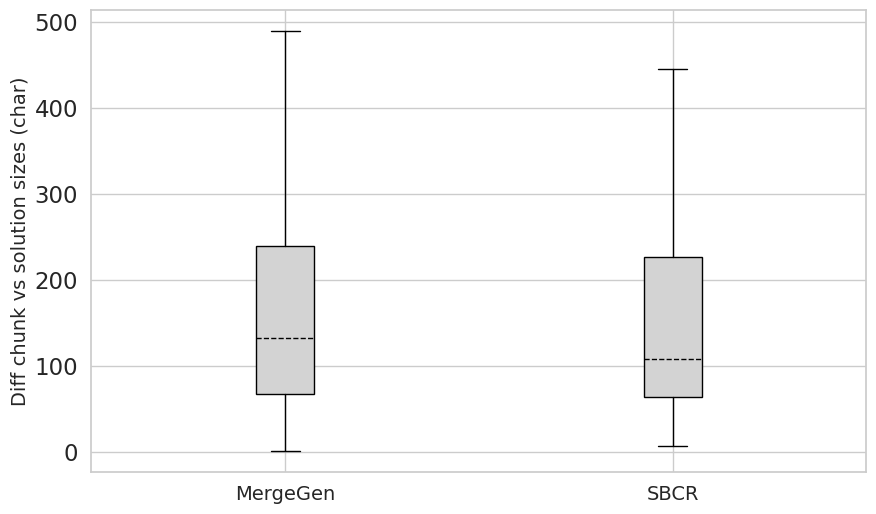

In [19]:
plt.figure(figsize=(10, 6))  # Set the figure size
plt.boxplot([df_mergegen['diff_chunk_solution'], df_sbcr['diff_chunk_solution']], 
            patch_artist=True,  # To fill the box with color
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  # Color of the median line
            boxprops=dict(facecolor='lightgray', color='black'),  # Color of the box
            whiskerprops=dict(color='black'),  # Color of the whiskers
            capprops=dict(color='black'),  # Color of the caps
            showfliers=False)  # Properties of the outliers

plt.ylabel('Diff chunk vs solution sizes (char)', fontsize=14)
plt.xticks([1, 2], ['MergeGen', 'SBCR'], fontsize=14)

plt.show()  # Show the plot

In [20]:
print(df_mergegen[['fitness_sbcr','diff_chunk_solution']].describe())
print(df_sbcr[['fitness_sbcr','diff_chunk_solution']].describe())
            

       fitness_sbcr  diff_chunk_solution
count    380.000000           380.000000
mean       0.717502           217.171053
std        0.179746           302.775629
min        0.333333             1.000000
25%        0.582923            66.750000
50%        0.773222           132.000000
75%        0.854240           240.000000
max        0.987155          2660.000000
       fitness_sbcr  diff_chunk_solution
count    131.000000           131.000000
mean       0.777303           343.954198
std        0.141471          1127.834350
min        0.405286             7.000000
25%        0.712156            64.000000
50%        0.799223           108.000000
75%        0.889964           227.000000
max        0.989362         11767.000000


In [21]:
df['fitness_to_solution_diff'] = df['mergegen_parents_sim'] - df['fitness_sbcr']

In [22]:
df[(df['diff'] < 0) & (df['mergegen_parents_sim'] > df['fitness_sbcr'])].sort_values('fitness_to_solution_diff', ascending=False)

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel,fitness_to_solution_diff
364,1369886,0.662605,0.899628,3.196719,5221,0.998243,0.626776,0.749335,-0.098614,21,...,268,-15,0.142857,0.857143,-0.714286,-598,0.167778,0.832222,-0.664444,0.086730
188,790398,0.894330,0.881890,1.566792,247,1.000000,0.398573,0.969731,-0.118110,9,...,236,3,0.666667,0.333333,0.333333,91,0.576988,0.423012,0.153976,0.075401
191,928167,0.861962,0.874702,4.852003,985,1.000000,0.877485,0.921344,-0.125298,36,...,795,-22,0.194444,0.805556,-0.611111,-415,0.364468,0.635532,-0.271065,0.059382
551,936821,0.863874,0.822827,5.019472,1328,1.000000,1.016312,0.921188,-0.177173,31,...,871,-5,0.419355,0.580645,-0.161290,-248,0.417001,0.582999,-0.165997,0.057314
237,1004937,0.927375,0.963434,2.155288,2413,0.977543,0.885866,0.982662,-0.014109,32,...,776,-2,0.468750,0.531250,-0.062500,-192,0.431721,0.568279,-0.136558,0.055287
46,1183009,0.790281,0.654070,0.535260,4457,1.000000,0.515921,0.842783,-0.345930,12,...,209,6,0.750000,0.250000,0.500000,251,0.688722,0.311278,0.377444,0.052502
484,841179,0.792059,0.896305,0.695406,826,1.000000,0.514178,0.842783,-0.103695,12,...,209,6,0.750000,0.250000,0.500000,251,0.688722,0.311278,0.377444,0.050724
128,1125436,0.794018,0.947250,1.075346,3842,1.000000,0.513620,0.842783,-0.052750,12,...,209,6,0.750000,0.250000,0.500000,251,0.688722,0.311278,0.377444,0.048764
15,1656424,0.762188,0.589827,8.117680,6240,1.000000,0.687931,0.807415,-0.410173,33,...,1364,-15,0.272727,0.727273,-0.454545,-819,0.285490,0.714510,-0.429020,0.045227
220,1060984,0.870192,0.824859,8.946598,2961,1.000000,0.137570,0.913659,-0.175141,4,...,93,-2,0.250000,0.750000,-0.500000,-40,0.379518,0.620482,-0.240964,0.043466


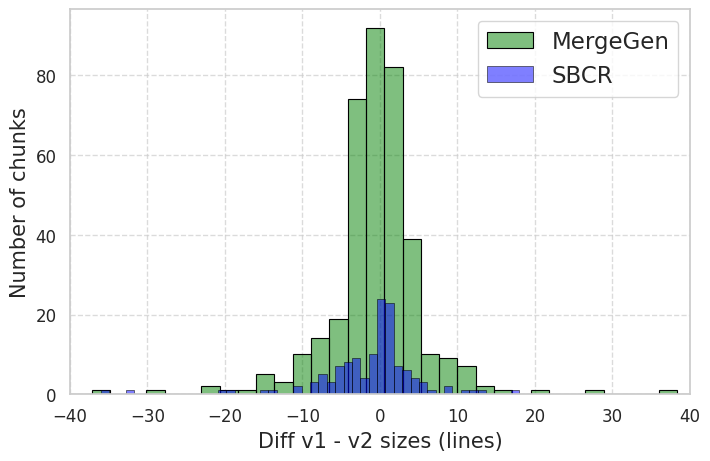

In [23]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_lines'], bins=50, color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_lines'],bins=50, color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (lines)', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(-40,40)
plt.legend()
plt.show()

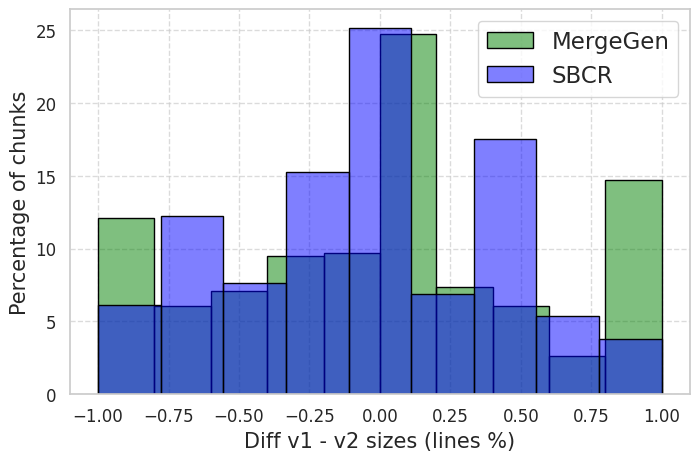

In [24]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_lines_rel'], stat='percent',color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_lines_rel'], stat='percent', color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (lines %)', fontsize=15)
plt.ylabel('Percentage of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
plt.legend()
plt.show()

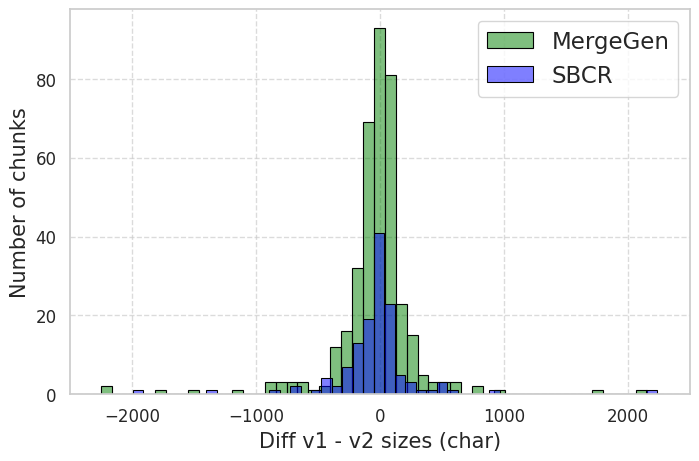

In [25]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_char'], bins=50, color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_char'],bins=50, color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (char)', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(-2500,2500)
plt.legend()
plt.show()

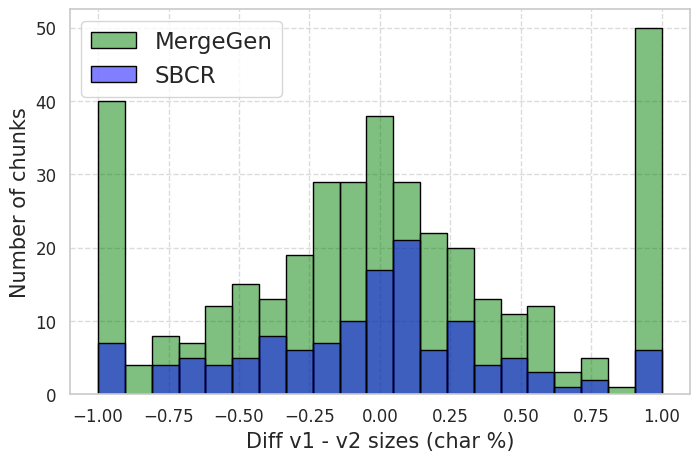

In [26]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_char_rel'], bins=21, color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_char_rel'], bins=21, color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (char %)', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
plt.legend()
plt.show()

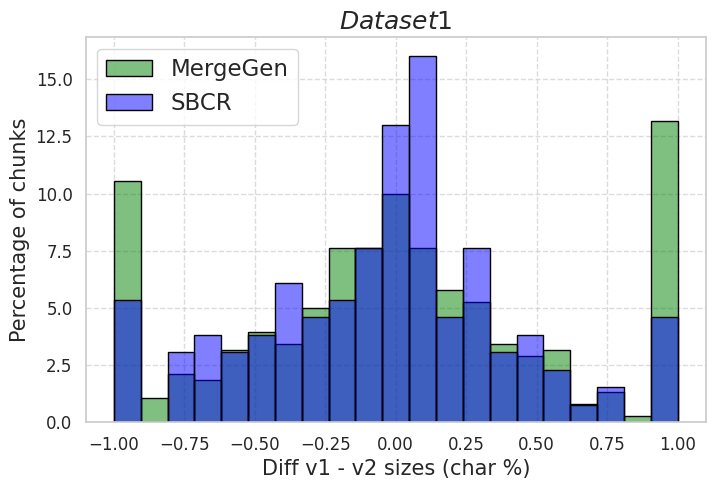

In [39]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_char_rel'], bins=21, stat='percent',color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_char_rel'], bins=21, stat='percent', color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.title('$Dataset1$')
plt.xlabel('Diff v1 - v2 sizes (char %)', fontsize=15)
plt.ylabel('Percentage of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
plt.legend()
plt.show()